# 04 Agrupacion de proveedores duplicados

Este notebook responde al objetivo específico 3: agrupar las llaves de proveedor que corresponden a la misma empresa y recalcular el gasto consolidado. Es un problema no supervisado, asi que se usa la agrupación aglomerativa de la práctica 3.

Cada proveedor (llave entidad + código) se compara con los demás por el nombre normalizado de la entrega 1 (mayúsculas, sin puntuacion y sin formas societarias como INC o LTD). La distancia entre dos proveedores es 1 menos la similitud de Levenshtein de sus nombres. Dos llaves de entidades distintas del Banco no se pueden unir, así que su distancia se fija en 1.

Cómo se evalúa (comentario de la entrega 1):

1. Con la silueta, para escoger el criterio de enlace.
2. Revisando que ningún grupo absorba demasiadas llaves (efecto cadena).
3. Con la revisión del Banco de los 20 grupos de mayor gasto, que marca si las llaves son la misma empresa.

Los nombres reales se usan solo en memoria para calcular las distancias. El notebook no imprime ningun nombre.


In [1]:
%pip install -r ../requirements.txt

  Using cached pandas-3.0.5-cp311-cp311-win_amd64.whl.metadata (19 kB)
Note: you may need to restart the kernel to use updated packages.


ERROR: Ignored the following yanked versions: 2.4.0
ERROR: Ignored the following versions that require a different python version: 1.21.2 Requires-Python >=3.7,<3.11; 1.21.3 Requires-Python >=3.7,<3.11; 1.21.4 Requires-Python >=3.7,<3.11; 1.21.5 Requires-Python >=3.7,<3.11; 1.21.6 Requires-Python >=3.7,<3.11; 2.5.0 Requires-Python >=3.12; 2.5.0rc1 Requires-Python >=3.12; 2.5.1 Requires-Python >=3.12; 2.5.2 Requires-Python >=3.12; 2.5.3 Requires-Python >=3.12; 2.5.4 Requires-Python >=3.12; 2.5.5 Requires-Python >=3.12
ERROR: Could not find a version that satisfies the requirement numpy==2.5.3 (from versions: 1.3.0, 1.4.1, 1.5.0, 1.5.1, 1.6.0, 1.6.1, 1.6.2, 1.7.0, 1.7.1, 1.7.2, 1.8.0, 1.8.1, 1.8.2, 1.9.0, 1.9.1, 1.9.2, 1.9.3, 1.10.0.post2, 1.10.1, 1.10.2, 1.10.4, 1.11.0, 1.11.1, 1.11.2, 1.11.3, 1.12.0, 1.12.1, 1.13.0, 1.13.1, 1.13.3, 1.14.0, 1.14.1, 1.14.2, 1.14.3, 1.14.4, 1.14.5, 1.14.6, 1.15.0, 1.15.1, 1.15.2, 1.15.3, 1.15.4, 1.16.0, 1.16.1, 1.16.2, 1.16.3, 1.16.4, 1.16.5, 1.16.6, 1.17

## 1. Configuracion y carga


In [2]:
import re
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from Levenshtein import ratio as lev_ratio
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
pd.set_option("display.width", 200)
pd.set_option("display.float_format","{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")
RAW_PATH = "../data/raw/Spend_FA_x_Transit_x_User_ID.xlsx"
REVISION_BANCO = "../data/raw/Revision_casos_duplicados_Banco_respuesta.xlsx"
MONTO="Invoice total with tax (CAD)"

raw_df = pd.read_excel(RAW_PATH, dtype={"Invoice Number": str})

def separar_proveedor(nombre):
    if pd.isna(nombre):
        return (np.nan, np.nan, np.nan)
    m = re.match(r"^(.*)_(\d+)_(\d+)$", nombre) or re.match(r"^.*\((.*)_(\d+)_(\d+)\)$", nombre)
    return (m.group(1).strip(),m.group(2),m.group(3)) if m else (nombre.strip(),np.nan,np.nan)

FORMAS_LEGALES = r"\b(INC|INCORPORATED|LTD|LTEE|LIMITED|LLC|LLP|LP|L P|ULC|CORP|CORPORATION|CO|COMPANY|SAS|S A S|SA|S A|SAA|SRL|S R L|SPA|LTDA|PLC|GMBH|BV|DE CV|S DE RL|THE)\b"
def normalizar_nombre(nombre):
    # mismas reglas de la entrega 1 para poder comparar los grupos
    if pd.isna(nombre):
        return np.nan
    n=re.sub(r"[^A-Z0-9 ]", " ", str(nombre).upper())
    n = re.sub(FORMAS_LEGALES, " ", n)
    return re.sub(r"\s+", " ", n).strip()
df=raw_df[["Invoice Supplier Name", "Invoice Status", MONTO]].copy()
df[["nombre","entidad","codigo"]] = pd.DataFrame(df["Invoice Supplier Name"].apply(separar_proveedor).tolist(),index=df.index)
df["llave"] = df["entidad"] + "_" + df["codigo"]
llaves=sorted(df["llave"].dropna().unique())
mapa = {k: f"PROV_{i:04d}" for i,k in enumerate(llaves,start=1)}  # mismos seudónimos que en la entrega 1
df["proveedor_id"]=df["llave"].map(mapa)
del raw_df

prov = (df.dropna(subset=["llave"]).groupby("proveedor_id")
            .agg(nombre=("nombre", "first"), entidad=("entidad", "first"), facturas=("llave", "size"))
            .reset_index())
gasto = df[df["Invoice Status"] == "approved"].groupby("proveedor_id")[MONTO].sum()
prov["gasto_aprobado"] = prov["proveedor_id"].map(gasto).fillna(0)
prov["nombre_norm"] = prov["nombre"].apply(normalizar_nombre)
prov=prov.drop(columns="nombre")  # desde aquí solo queda el nombre normalizado y no se imprime
print(f"Proveedores: {len(prov):,} | entidades del Banco: {prov['entidad'].nunique()} | gasto aprobado: {prov['gasto_aprobado'].sum() / 1e6:,.1f} millones de CAD")

Proveedores: 3,354 | entidades del Banco: 4 | gasto aprobado: 11,168.6 millones de CAD


## 2. Matriz de distancias

Distancia = 1 − similitud de Levenshtein entre los nombres normalizados, solo dentro de la misma entidad. Entre entidades distintas la distancia es 1.


In [3]:
n = len(prov)
# entre entidades distintas la distancia es 1: no es un duplicado del maestro
D = np.ones((n, n))
np.fill_diagonal(D, 0)
nombres = prov["nombre_norm"].fillna("").tolist()
for ent, idx in prov.groupby("entidad").indices.items():
    for a in range(len(idx)):
        for b in range(a + 1,len(idx)):
            i,j = idx[a],idx[b]
            D[i, j]=D[j, i]=1 - lev_ratio(nombres[i], nombres[j])
sup = D[np.triu_indices(n,1)]
print(f"Matriz de {n:,} x {n:,} | pares con el mismo nombre normalizado: {int((sup == 0).sum()):,} | pares con similitud >= 0,90: {int((sup <= 0.10).sum()):,}")

Matriz de 3,354 x 3,354 | pares con el mismo nombre normalizado: 36 | pares con similitud >= 0,90: 68


## 3. Escogencia del enlace y del umbral

Como no se sabe cuántas empresas hay, el corte se hace con distance_threshold (n_clusters=None). El umbral es la distancia máxima para unir dos grupos: 0,10 equivale a nombres con al menos 90% de similitud. Ward no se usa porque solo admite distancia euclidiana; se comparan los enlaces complete y average, y también single para mostrar el efecto cadena.

Para cada combinación se calculan la silueta con la matriz de distancias, el numero de grupos con mas de una llave, el tamaño del grupo más grande y el gasto que queda en grupos con varias llaves.


In [4]:
filas = []
for enlace in ["single", "complete", "average"]:
    for umbral in [0.05,0.10,0.15,0.20]:
        modelo = AgglomerativeClustering(n_clusters=None, distance_threshold=umbral, linkage=enlace, metric="precomputed")
        etiquetas = modelo.fit_predict(D)
        tam = pd.Series(etiquetas).value_counts()
        multi = tam[tam > 1].index
        filas.append({"enlace": enlace, "umbral": umbral, "grupos": modelo.n_clusters_,
                     "grupos con 2+ llaves": len(multi), "llaves en esos grupos": int(tam[tam > 1].sum()),
                        "grupo más grande": int(tam.max()),"silueta": silhouette_score(D,etiquetas,metric="precomputed"),
                      "% gasto en grupos con 2+ llaves": prov.loc[np.isin(etiquetas, multi), "gasto_aprobado"].sum() / prov["gasto_aprobado"].sum() * 100})
comparacion = pd.DataFrame(filas)
comparacion

,enlace,umbral,grupos,grupos con 2+ llaves,llaves en esos grupos,grupo más grande,silueta,% gasto en grupos con 2+ llaves
0,single,0.050,3316,31,69,5,0.019,8.347
1,single,0.100,3297,48,105,5,0.025,10.710
2,single,0.150,3213,111,252,7,0.041,16.288
3,single,0.200,2924,172,602,61,0.046,39.846
4,complete,0.050,3317,32,69,5,0.019,8.347
5,complete,0.100,3299,48,103,5,0.025,10.704
6,complete,0.150,3228,114,240,6,0.041,16.125
7,complete,0.200,3073,235,516,6,0.062,36.803
8,average,0.050,3317,32,69,5,0.019,8.347
9,average,0.100,3299,48,103,5,0.025,10.704


La silueta no basta para escoger el umbral en este problema. Casi todos los proveedores quedan solos en su grupo, y scikit-learn le asigna silueta 0 a un grupo de un solo elemento. Por eso la silueta sube siempre que se sube el umbral: une más llaves aunque sean empresas distintas. Con umbral 0,20 (80% de similitud) se unen nombres que solo comparten palabras genéricas, y el gasto "duplicado" salta a más de un tercio del total, lo que no es creible.

Cómo llegamos al umbral de 0,10. Probamos los tres enlaces con cuatro umbrales (tabla de arriba):

- Con 0,05 salen 32 grupos y 8,3% del gasto. Es muy estricto: deja por fuera nombres que solo cambian en una letra o una abreviatura.
- Con 0,10 salen 48 grupos, 10,7% del gasto y el grupo más grande tiene 5 llaves. Es la misma regla de 90% de similitud de la entrega 1.
- Con 0,15 los grupos se duplican (113) y el gasto sube a 16%.
- Con 0,20 la silueta es la más alta, pero se juntaría el 36,5% del gasto, y con enlace single sale un grupo de 61 llaves (efecto cadena). Que un tercio del gasto sea del mismo proveedor repetido no es creíble.

Lo que no funcionó fue escoger el umbral solo con la silueta: sube siempre porque scikit-learn le da 0 a los grupos de una llave. Entonces usamos la silueta para el enlace (average, que nunca hace cadena) y fijamos el umbral en 0,10. Es la regla que se usó en el Excel de 20 grupos que le mandamos al Banco, así que su respuesta valida directamente esta decisión. [Equipo: completar lo que dijo el Banco sobre los grupos.] Los umbrales 0,15 y 0,20 quedan como el rango superior del gasto que podría estar sin consolidar.


In [5]:
ENLACE,UMBRAL = "average",0.10  # 0,10 y no 0,20: con 0,20 la silueta subía pero se juntaba demasiado gasto
elegida = comparacion[(comparacion["enlace"] == ENLACE) & (comparacion["umbral"] == UMBRAL)].iloc[0]
print(f"Configuración escogida: enlace {ENLACE}, umbral {UMBRAL} (similitud de nombre >= {1 - UMBRAL:.0%}) | "
    f"silueta {elegida['silueta']:.3f} | grupo más grande {elegida['grupo más grande']} llaves")

Configuración escogida: enlace average, umbral 0.1 (similitud de nombre >= 90%) | silueta 0.025 | grupo más grande 5 llaves


## 4. Dendrograma

Se dibuja para la entidad con mas proveedores, con el mismo enlace y truncado a las ultimas 30 uniones para que se pueda leer. La línea roja marca el umbral escogido.


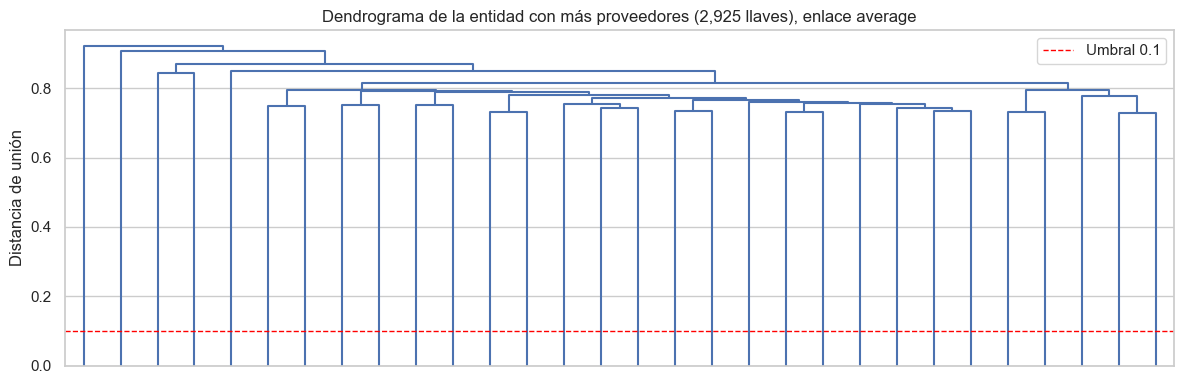

In [6]:
ent_grande = prov["entidad"].value_counts().index[0]
idx = prov.index[prov["entidad"] == ent_grande].to_numpy()
jerarquia=linkage(squareform(D[np.ix_(idx,idx)],checks=False),method=ENLACE)
plt.figure(figsize=(12,4))
dendrogram(jerarquia, truncate_mode="lastp", p=30, no_labels=True)
plt.axhline(UMBRAL,color="red",ls="--",lw=1,label=f"Umbral {UMBRAL}")
plt.ylabel("Distancia de unión"); plt.title(f"Dendrograma de la entidad con más proveedores ({len(idx):,} llaves), enlace {ENLACE}")
plt.legend(); plt.tight_layout(); plt.show()

La mayoría de las uniones ocurren a distancias altas, porque casi todos los proveedores tienen nombres muy distintos. Solo unas pocas uniones quedan por debajo del umbral, que son las llaves con nombre igual o casi igual.


## 5. Grupos resultantes y gasto consolidado


In [7]:
modelo = AgglomerativeClustering(n_clusters=None, distance_threshold=UMBRAL, linkage=ENLACE, metric="precomputed")
prov["grupo"] = modelo.fit_predict(D)
tam = prov["grupo"].value_counts()
prov["llaves_en_grupo"] = prov["grupo"].map(tam)
multi = prov[prov["llaves_en_grupo"] > 1]
grupos = (multi.groupby("grupo").agg(llaves=("proveedor_id", "size"), gasto_aprobado=("gasto_aprobado", "sum"),
                                     facturas=("facturas", "sum"), entidad=("entidad", "first"))
             .sort_values("gasto_aprobado", ascending=False))
grupos.index = [f"GRUPO_P{i:03d}" for i in range(1, len(grupos) + 1)]
print(f"Grupos con 2 o más llaves: {len(grupos)} | llaves involucradas: {int(grupos['llaves'].sum())} | "
    f"gasto en esos grupos: {grupos['gasto_aprobado'].sum() / 1e6:,.1f} millones de CAD "
        f"({grupos['gasto_aprobado'].sum() / prov['gasto_aprobado'].sum():.1%} del gasto aprobado)")
grupos.head(20)

Grupos con 2 o más llaves: 48 | llaves involucradas: 103 | gasto en esos grupos: 1,195.5 millones de CAD (10.7% del gasto aprobado)


,llaves,gasto_aprobado,facturas,entidad
GRUPO_P001,2,"524,582,978.360",748,10001
GRUPO_P002,5,"197,142,141.180",378,10001
GRUPO_P003,2,"187,244,184.060",838,10001
GRUPO_P004,2,"78,565,723.900",1158,10001
GRUPO_P005,2,"49,528,370.870",268,10001
GRUPO_P006,2,"38,645,967.130",108,10001
GRUPO_P007,2,"34,857,176.790",447,10001
GRUPO_P008,2,"13,705,255.230",439,10001
GRUPO_P009,2,"13,044,767.050",39,10001
GRUPO_P010,2,"8,318,816.580",120,10001


Qué cambia en el ranking de proveedores. Si se suman las llaves de cada grupo, algunas empresas suben en el ranking de gasto. Esto es lo que el área de Procurement necesita para negociar con el gasto real de cada empresa.


In [8]:
prov["empresa"] = np.where(prov["llaves_en_grupo"] > 1, "G" + prov["grupo"].astype(str), prov["proveedor_id"])
rank_antes = prov.sort_values("gasto_aprobado",ascending=False).reset_index(drop=True)
rank_despues = prov.groupby("empresa")["gasto_aprobado"].sum().sort_values(ascending=False).reset_index()
print(f"Gasto de los 10 proveedores más grandes: antes {rank_antes['gasto_aprobado'].head(10).sum() / prov['gasto_aprobado'].sum():.1%} "
    f"| después de consolidar {rank_despues['gasto_aprobado'].head(10).sum() / prov['gasto_aprobado'].sum():.1%}")
print(f"Empresas distintas: antes {len(prov):,} llaves | después {len(rank_despues):,}")

Gasto de los 10 proveedores más grandes: antes 31.9% | después de consolidar 32.9%
Empresas distintas: antes 3,354 llaves | después 3,299


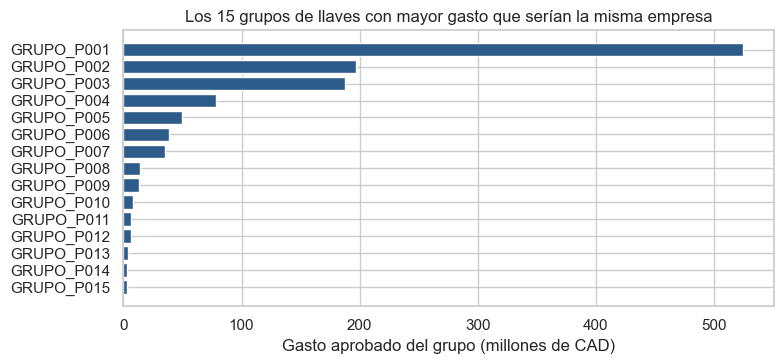

In [9]:
fig,ax = plt.subplots(figsize=(8,3.8))
top = grupos.head(15)
ax.barh(top.index[::-1], top["gasto_aprobado"][::-1] / 1e6, color="#2E5C8A")
ax.set_xlabel("Gasto aprobado del grupo (millones de CAD)")
ax.set_title("Los 15 grupos de llaves con mayor gasto que serían la misma empresa")
plt.tight_layout(); plt.show()

## 6. Validación con el Banco

El Excel de revisión trae los 20 grupos de mayor gasto encontrados con la misma regla (nombre normalizado igual o con similitud de 0,90 o más). Cuando el Banco lo devuelva, esta celda calcula cuántos grupos se confirman como la misma empresa y el gasto consolidado validado, que es el KPI 1.


In [10]:
if os.path.exists(REVISION_BANCO):
    rev = pd.read_excel(REVISION_BANCO, sheet_name="Proveedores")
    resp = rev.groupby("Grupo")["¿Es la misma empresa?"].first().dropna()
    print(f"Grupos revisados: {resp.isin(['Sí', 'No']).sum()} | confirmados: {(resp == 'Sí').sum()}")
else:
    print("Pendiente: el Banco todavía no ha devuelto la revisión.")

Pendiente: el Banco todavía no ha devuelto la revisión.


## 7. Resumen

- La agrupación aglomerativa con la distancia de Levenshtein encuentra las llaves de proveedor con nombre igual o casi igual dentro de la misma entidad del Banco.
- El enlace se escogió por silueta (average). El umbral se fijo en 90% de similitud, la regla de la entrega 1, porque en este problema la silueta sube siempre con el umbral y no sirve sola para escoger el corte.
- El alcance es dentro de cada entidad del Banco: dos llaves en entidades distintas pueden ser el mismo proveedor contratado por dos sociedades, y eso no es un duplicado del maestro. Por eso el porcentaje es menor que el 24,4% de la entrega 1, que contaba nombres repetidos tambien entre entidades.
- El gasto en grupos con varias llaves es un gasto sin consolidar y todavía no validado, como señalo el comentario de la entrega 1. Solo se vuelve gasto consolidado cuando el Banco confirma que las llaves son la misma empresa.
- El nombre no basta para confirmar: dos empresas distintas pueden tener nombres parecidos. Por eso la validacion del Banco es parte del proceso y un maestro de proveedores con identificación tributaria mejoraría el resultado.